# 🩸BOTS Dataset Projects (Blood Order Transfusion system)

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
from google.colab import files
uploaded = files.upload()
print("✅ File uploaded!")

Saving MP_BOTS_Data_14072026.xlsx to MP_BOTS_Data_14072026.xlsx
✅ File uploaded!


In [ ]:
df_master = pd.read_excel('MP_BOTS_Data_14072026.xlsx', sheet_name='BOTS Master Data')
df_details = pd.read_excel('MP_BOTS_Data_14072026.xlsx', sheet_name='BOTS Details Data')
print("✅ Data loaded successfully!")
print(df_master.shape)
print(df_details.shape)

✅ Data loaded successfully!
(3792, 33)
(9625, 36)


In [ ]:
df_master.head(5)

,Blood Bank Name,Patient Name,Patient ID,Admission Number,Order Number,Age,Age Type,Gender,Requsted Component,BOTS Request Datetime,...,Bag Id,Issued Component Name,BOTS Bag Recive Date,Safetrans Issue BOTS Receive time duration,Trans Start Date,Start Vital Details,Trans End Date,End Vital Details,Adverse Reaction,Adverse Reaction Date
0,District Hospital Blood Center Khargone,SHIVKANYA DHARMEDRA,3390/122,0,R25-16709,28,Year,Female,PRBC(1),2025-12-15 16:50:00,...,DHK25-014974,PRBC,NaT,NaN,NaT,NaN,NaN,NaN,NaN,NaN
1,District Hospital Blood Center Khargone,BAHADAR RUKHDIYA KAVACHHE,202569879,0,R25-16738,40,Year,Male,PRBC(1),2025-12-16 12:58:00,...,DHK25-015753,PRBC,NaT,NaN,NaT,NaN,NaN,NaN,NaN,NaN
2,District Hospital Blood Center Khargone,RIYANSH LAKHAN,1082/49,0,R25-16746,11,Year,Male,PRBC(1),2025-12-16 14:15:00,...,DHK25-015311,PRBC,NaT,NaN,NaT,NaN,NaN,NaN,NaN,NaN
3,District Hospital Blood Center Khargone,BHUMIKA CHINTARAM,6188,0,R25-16753,6,Month,Female,PRBC(1),2025-12-16 16:18:00,...,DHK25-015791,PRBC,NaT,NaN,NaT,NaN,NaN,NaN,NaN,NaN
4,District Hospital Blood Center Khargone,SURESH bau YADAV,20250289744,0,R25-16826,55,Year,Male,PRBC(1),2025-12-18 13:18:00,...,DHK25-015130,PRBC,2025-12-18 14:34:00,0 hrs 0 mins,NaT,NaN,NaN,NaN,NaN,NaN


In [ ]:
for col in df_master.columns:
  print(" -", col)

 - Blood Bank Name
 - Patient Name
 - Patient ID
 - Admission Number
 - Order Number
 - Age
 - Age Type
 - Gender
 - Requsted Component
 - BOTS Request Datetime
 - Safetrans Confirmation datetime
 - BOTS Request to Safetrans confirmation
 - BOTS Requseted BG
 - Safetrans Tested BG
 - Blood Group Discrepancy
 - BG Test Date
 - BG Validation Date
 - CM Test Date
 - CM Validation Date
 - Issue SrNo
 - Issue Detail SrNo
 - Safetras Issue Date
 - BOTS Request to Issue Duration
 - Bag Id
 - Issued Component Name
 - BOTS Bag Recive Date
 - Safetrans Issue BOTS Receive time duration
 - Trans Start Date
 - Start Vital Details
 - Trans End Date
 - End Vital Details
 - Adverse Reaction
 - Adverse Reaction Date


In [ ]:
df_master.isnull().sum()

,0
Blood Bank Name,0
Patient Name,0
Patient ID,0
Admission Number,0
Order Number,0
Age,0
Age Type,0
Gender,0
Requsted Component,0
BOTS Request Datetime,0


In [ ]:
df_master.dtypes

,0
Blood Bank Name,object
Patient Name,object
Patient ID,object
Admission Number,object
Order Number,object
Age,int64
Age Type,object
Gender,object
Requsted Component,object
BOTS Request Datetime,datetime64[ns]


In [ ]:
# --- Check if Issue Detail SrNo has duplicate values ---

total_rows = len(df_master)
unique_values = df_master['Issue Detail SrNo'].nunique()
duplicate_count = df_master.duplicated(subset=['Issue Detail SrNo']).sum()

print("Total Rows              :", total_rows)
print("Unique Issue Detail SrNo:", unique_values)
print("Duplicate Count         :", duplicate_count)

Total Rows              : 3792
Unique Issue Detail SrNo: 3759
Duplicate Count         : 33


In [ ]:
# --- Show which Issue Detail SrNo values appear more than once ---

duplicates = df_master[df_master.duplicated(subset=['Issue Detail SrNo'], keep=False)]
print("Rows with duplicate Issue Detail SrNo:")
print(duplicates[['Issue Detail SrNo', 'Patient Name', 'Order Number', 'Issued Component Name']].sort_values('Issue Detail SrNo'))

Rows with duplicate Issue Detail SrNo:
     Issue Detail SrNo           Patient Name Order Number  \
147              15672    SUMIT RAV VAY DANDE     R25-6952   
148              15672    SUMIT RAV VAY DANDE     R25-6952   
163              15694              AYUSH - -     R25-6980   
162              15694              AYUSH - -     R25-6980   
222              15792      DEEPAK   PRAKASH      R25-7087   
..                 ...                    ...          ...   
11               36675  RANI AMARDEEP  RAWAT     R25-16862   
108              36829        ANKESH   PATEL     R23-13698   
109              36829        ANKESH   PATEL     R23-13698   
135              36992         GUNJAN   GOND     R23-13892   
14               36992   ALISHABA SALIM SALIM    R25-17210   

    Issued Component Name  
147                  PRBC  
148                  PRBC  
163                  PRBC  
162                  PRBC  
222                   FFP  
..                    ...  
11                  

In [ ]:
df_master_clean = df_master.drop_duplicates(
    subset=['Patient Name', 'Order Number', 'Issue Detail SrNo'],
    keep='first'
)

print("Rows before cleaning:", len(df_master))
print("Rows after cleaning :", len(df_master_clean))
print("Rows removed        :", len(df_master) - len(df_master_clean))

Rows before cleaning: 3792
Rows after cleaning : 3761
Rows removed        : 31


In [ ]:
# --- Check rows where ALL 33 columns are exactly same ---

full_duplicates = df_master.duplicated(keep=False)
print("Fully identical duplicate rows:", full_duplicates.sum())

Fully identical duplicate rows: 11


In [ ]:
# --- Remove only rows where ALL columns are exactly same ---

df_master_clean = df_master.drop_duplicates(keep='first')

print("Rows before cleaning:", len(df_master))
print("Rows after cleaning :", len(df_master_clean))
print("Rows removed        :", len(df_master) - len(df_master_clean))

Rows before cleaning: 3792
Rows after cleaning : 3786
Rows removed        : 6


In [ ]:
# --- Same patient same order number ---

dup_patient_order = df_master.duplicated(
    subset=['Patient Name', 'Order Number'],
    keep=False
)
print("Duplicate by Patient + Order Number:", dup_patient_order.sum())
df_master[dup_patient_order][['Patient Name', 'Order Number', 'Issue Detail SrNo', 'Issued Component Name']].sort_values('Order Number')

Duplicate by Patient + Order Number: 99


,Patient Name,Order Number,Issue Detail SrNo,Issued Component Name
67,BHUMIKA BAHRANI BAHRANI,R23-13352,36483,PRBC
66,BHUMIKA BAHRANI BAHRANI,R23-13352,36478,PRBC
57,LAXMI YADAV YADAV,R23-13356,36465,PRBC
58,LAXMI YADAV YADAV,R23-13356,36553,PRBC
104,RAMKALI SONDHIYA,R23-13653,36795,PRBC
...,...,...,...,...
28,PRINCE BHOLA,R26-822,37960,PRBC
34,HUSEIN VAJID,R26-987,38114,PRBC
35,HUSEIN VAJID,R26-987,38149,PRBC
36,ATHARV ASHIS,R26-988,38119,PRBC


In [ ]:
# --- Same Bag ID contain to 2 patients ---

dup_bag = df_master.duplicated(subset=['Bag Id'], keep=False)
print("Duplicate Bag IDs:", dup_bag.sum())
df_master[dup_bag][['Bag Id', 'Patient Name', 'Order Number', 'Issued Component Name']].sort_values('Bag Id')

Duplicate Bag IDs: 717


,Bag Id,Patient Name,Order Number,Issued Component Name
68,DHS25-012272,ANPURNA SINGH CHOUHAN,R23-13375,PRBC-P2
84,DHS25-012272,HARDIK SINGH,R23-13468,PRBC
50,DHS25-012287,RITESH NAYAK NAYAK,R23-13315,RDP
64,DHS25-012287,GANESHIYA KUSHWAHA,R23-13376,PRBC
70,DHS25-012341,RITESH NAYAK,R23-13400,RDP
...,...,...,...,...
3702,DHU26-003588,NAITIK MUKESH,R26-4391,PRBC-Aliquot-A
3700,DHU26-003615,PARIDHI ISHAN PAWAR,R26-4390,PRBC-Aliquot-A
3661,DHU26-003615,MRITYUNJAY VIRENDRA,R26-4331,PRBC
3699,DHU26-003654,BABLI DHARMENDRA,R26-4388,PLT


In [ ]:
# --- This function converts "2 hrs 54 mins" → 174 (minutes) ---

def parse_duration(text):
    if pd.isna(text):
        return None
    text = str(text)
    hrs = 0
    mins = 0
    if 'hrs' in text:
        hrs = int(text.split('hrs')[0].strip())
    if 'mins' in text:
        mins = int(text.split('mins')[0].split()[-1].strip())
    return (hrs * 60) + mins  # total minutes

# Apply this function to duration column
df_master['TAT_minutes'] = df_master['BOTS Request to Issue Duration'].apply(parse_duration)

print("✅ Duration converted to minutes!")
print(df_master['TAT_minutes'].describe())

✅ Duration converted to minutes!
count     3792.000000
mean       193.385549
std       1840.649728
min          2.000000
25%         68.000000
50%         85.000000
75%        121.000000
max      97819.000000
Name: TAT_minutes, dtype: float64


In [ ]:
# --- Remove only clearly wrong entries (above 72 hours = 3 days) ---
# 1630 hrs and 916 hrs are obvious data entry mistakes

# Ensure 'TAT_minutes' is present in df_master_clean
df_master_clean['TAT_minutes'] = df_master_clean['BOTS Request to Issue Duration'].apply(parse_duration)

before = len(df_master_clean)

df_master_clean = df_master_clean[df_master_clean['TAT_minutes'] <= 4320]  # 72 hours

after = len(df_master_clean)

print("Rows before:", before)
print("Rows after :", after)
print("Removed    :", before - after)
print()
print("TAT Summary after cleaning:")
print(df_master_clean['TAT_minutes'].describe())

Rows before: 3786
Rows after : 3784
Removed    : 2

TAT Summary after cleaning:
count    3784.000000
mean      152.725951
std       281.116864
min         2.000000
25%        68.000000
50%        85.000000
75%       120.250000
max      4262.000000
Name: TAT_minutes, dtype: float64


/tmp/ipykernel_997/1739196588.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_master_clean['TAT_minutes'] = df_master_clean['BOTS Request to Issue Duration'].apply(parse_duration)


In [ ]:
# --- Group ages into categories ---

bins   = [0,  1,  12,  18,  40,  60, 101]
labels = ['Newborn', 'Child', 'Teen', 'Adult', 'Middle-Age', 'Senior']

df_master['Age_Group'] = pd.cut(df_master['Age'], bins=bins, labels=labels, right=False)

print("✅ Age Groups created!")
print(df_master['Age_Group'].value_counts())

✅ Age Groups created!
Age_Group
Adult         1324
Child         1308
Teen           624
Middle-Age     373
Senior         152
Newborn         11
Name: count, dtype: int64


In [ ]:
# --- Extract Month from BOTS Request Date ---

df_master['Month'] = df_master['BOTS Request Datetime'].dt.to_period('M')

print("✅ Month column created!")
print(df_master['Month'].value_counts().sort_index())

✅ Month column created!
Month
2025-12    341
2026-01    527
2026-02    465
2026-03    506
2026-04    528
2026-05    579
2026-06    590
2026-07    256
Freq: M, Name: count, dtype: int64


In [ ]:
# --- Fill empty Blood Group Discrepancy with "No" ---
# Empty means no discrepancy was found

df_master['Blood Group Discrepancy'] = df_master['Blood Group Discrepancy'].fillna('No')

print("✅ Done!")
print(df_master['Blood Group Discrepancy'].value_counts())

✅ Done!
Blood Group Discrepancy
No     3762
Yes      30
Name: count, dtype: int64


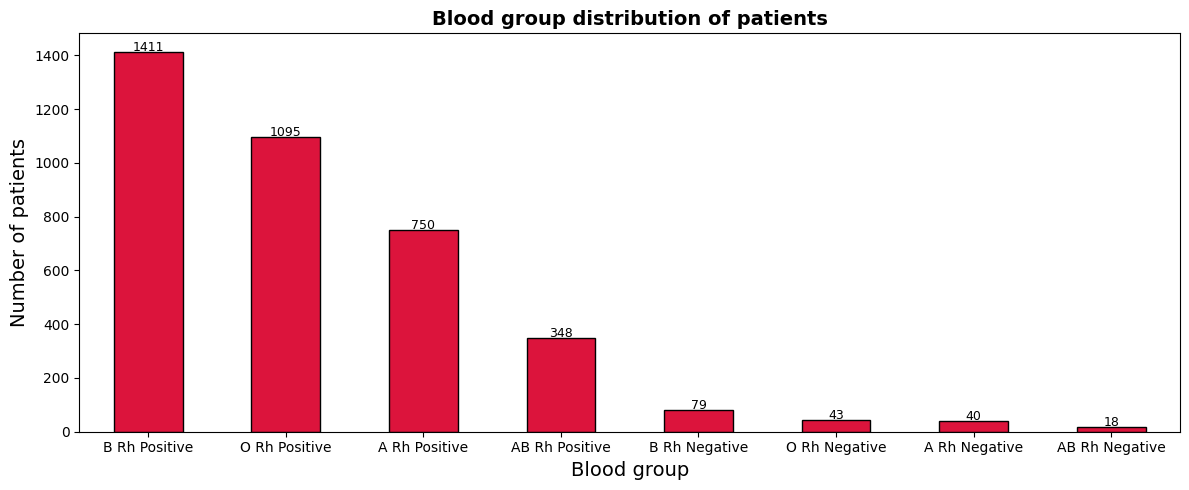

In [ ]:
# Graph 1 - Blood group Distribution
plt.figure(figsize=(12,5))
bg_counts = df_master_clean['Safetrans Tested BG'].value_counts()
bg_counts.plot(kind='bar', color='crimson',edgecolor = 'black')
plt.title('Blood group distribution of patients', fontsize = 14 , fontweight = 'bold')
plt.xlabel('Blood group',fontsize = 14)
plt.ylabel('Number of patients',fontsize = 14)
plt.xticks(rotation = 360 )
for i, val in enumerate(bg_counts):
  plt.text(i,val+5,str(val),ha='center',fontsize = 9)
plt.tight_layout()
plt.show()

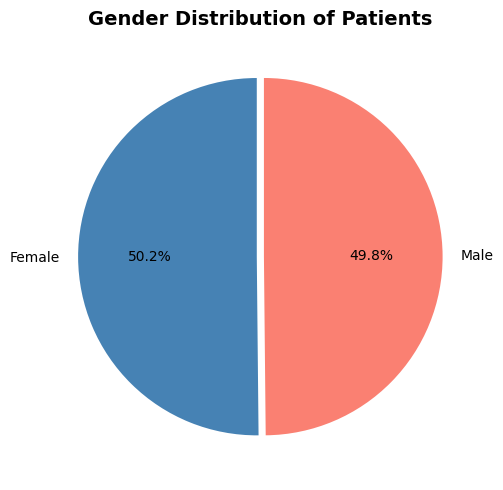

In [ ]:
# Graph 2 - Gender Distribution
plt.figure(figsize=(12,5))
gender_counts = df_master_clean['Gender'].value_counts()
colors = ['steelblue','salmon']
plt.pie(gender_counts,labels = gender_counts.index,autopct = '%1.1f%%',colors = colors,startangle = 90,explode = (0.02,0.02))
plt.title('Gender Distribution of Patients',fontsize = 14 , fontweight = 'bold')
plt.tight_layout()
plt.show()

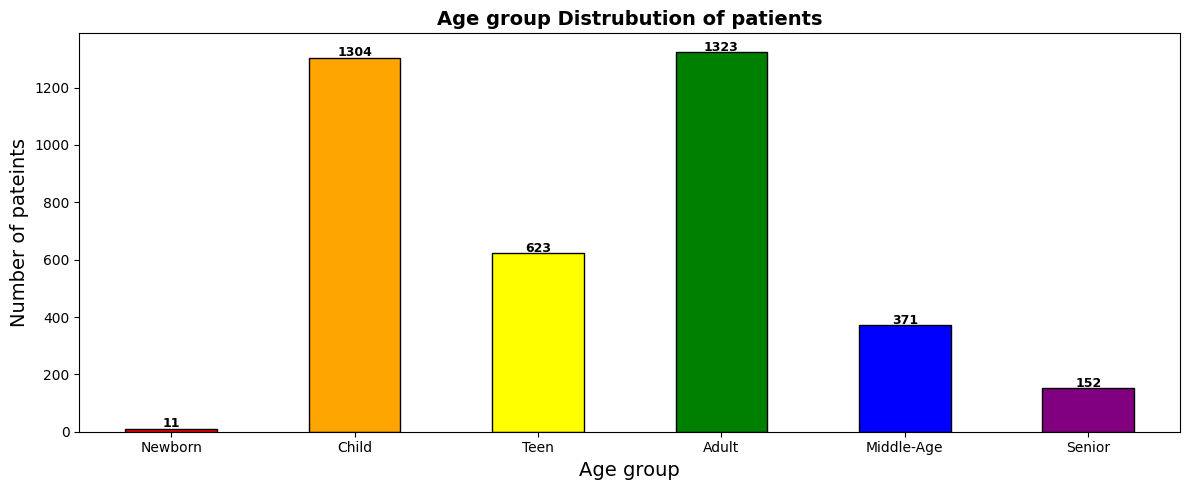

In [ ]:
# Age group  Distribution
plt.figure(figsize=(12,5))
df_master_clean['Age_Group'] = pd.cut(df_master_clean['Age'],bins=bins,labels=labels,right=False)
age_order = ['Newborn','Child','Teen','Adult','Middle-Age','Senior']
age_counts = df_master_clean['Age_Group'].value_counts().reindex(age_order)
colors = ['red','orange','yellow','Green','Blue','Purple']
age_counts.plot(kind = 'bar',color = colors , edgecolor = 'black')
plt.title('Age group Distrubution of patients',fontsize = 14 , fontweight = 'bold')
plt.xlabel('Age group',fontsize = 14)
plt.ylabel('Number of pateints',fontsize =14)
plt.xticks(rotation=0)
for i,val in enumerate(age_counts):
  plt.text(i,val+5,str(val),ha='center',fontsize = 9,fontweight = 'bold')
plt.tight_layout()
plt.show()

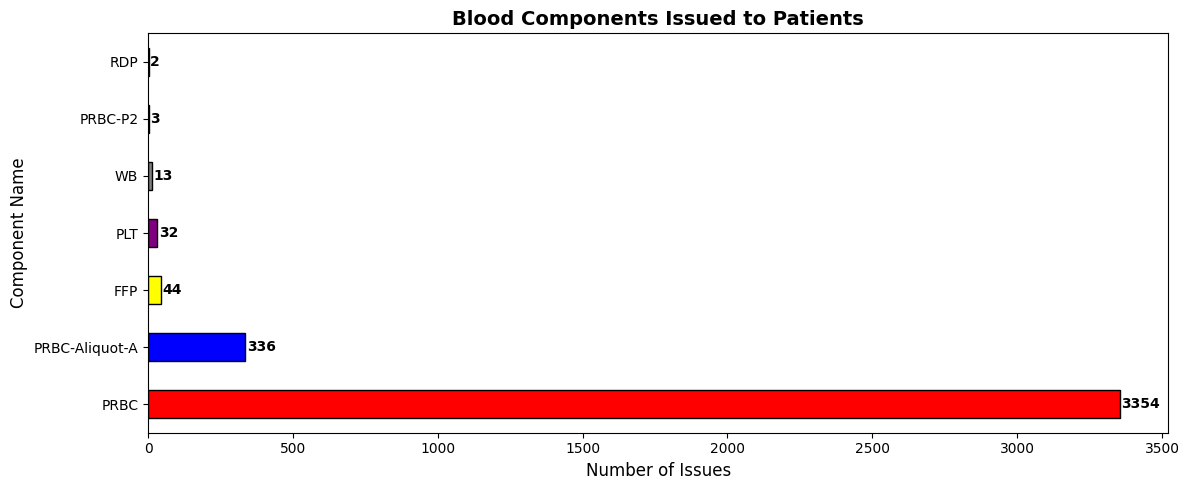

In [ ]:
# graph 4 - Blood Component Issued
plt.figure(figsize=(12, 5))
component_counts = df_master_clean['Issued Component Name'].value_counts()
colors = ['Red', 'Blue', 'yellow', 'purple', 'grey', 'green']
component_counts.plot(kind='barh', color=colors, edgecolor='black')
plt.title('Blood Components Issued to Patients', fontsize=14, fontweight='bold')
plt.xlabel('Number of Issues', fontsize=12)
plt.ylabel('Component Name', fontsize=12)
for i, val in enumerate(component_counts):
    plt.text(val + 5, i, str(val), va='center', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

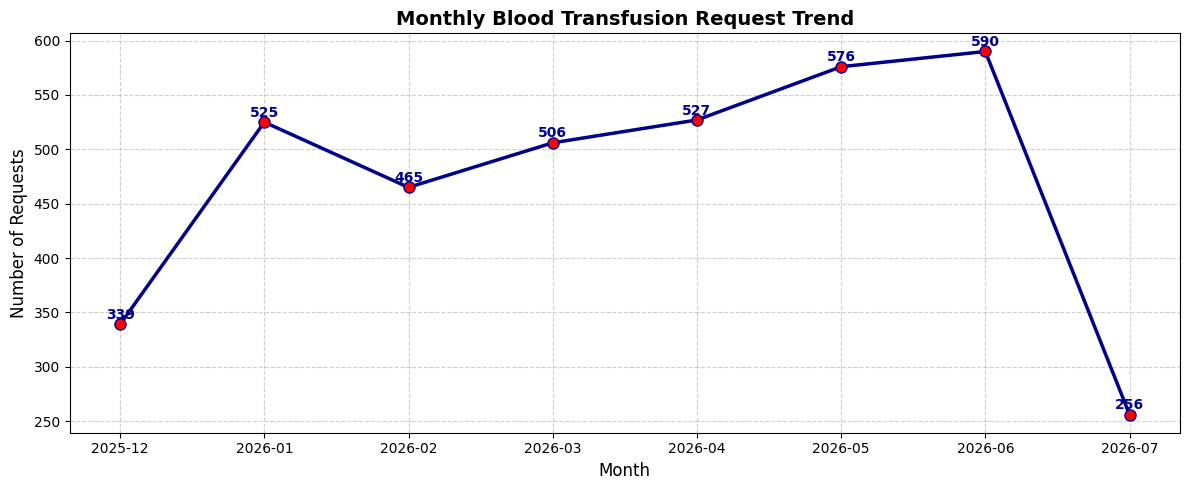

In [ ]:
# Graph 5 : Monthly Request Trend

plt.figure(figsize=(12, 5))
df_master_clean['Month'] = df_master_clean['BOTS Request Datetime'].dt.to_period('M')
monthly_counts = df_master_clean['Month'].value_counts().sort_index()
plt.plot(monthly_counts.index.astype(str),
         monthly_counts.values,
         marker='o',
         color='darkblue',
         linewidth=2.5,
         markersize=8,
         markerfacecolor='red')
plt.title('Monthly Blood Transfusion Request Trend', fontsize=14, fontweight='bold')
plt.xlabel('Month', fontsize=12)
plt.ylabel('Number of Requests', fontsize=12)
plt.xticks(rotation=0)
for i, (month, val) in enumerate(zip(monthly_counts.index.astype(str), monthly_counts.values)):
    plt.text(i, val + 5, str(val), ha='center', fontsize=10, fontweight='bold', color='darkblue')
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

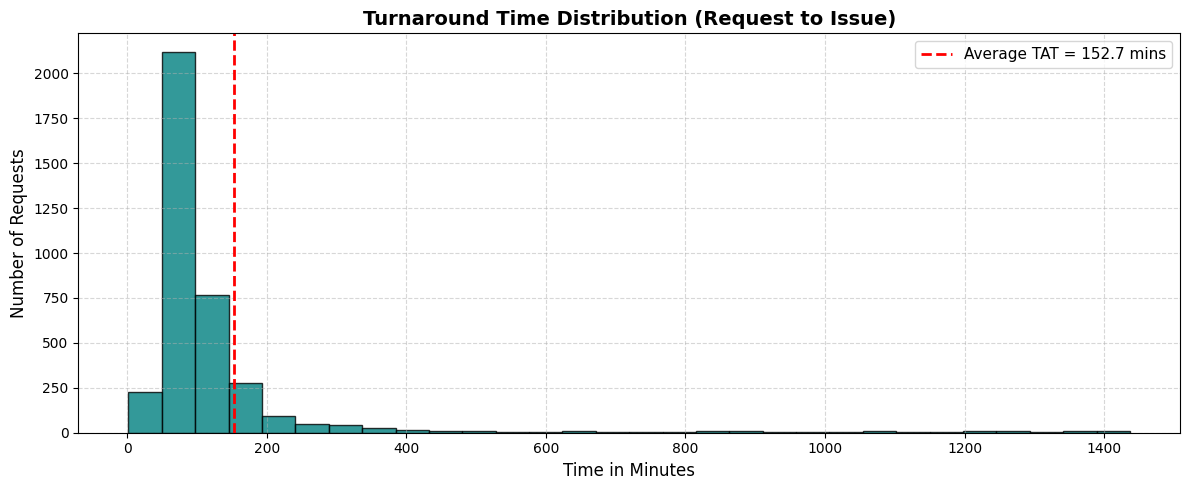

In [ ]:
# Graph 6 : TAT Distribution Histogram

plt.figure(figsize=(12, 5))
tat_data = df_master_clean[df_master_clean['TAT_minutes'] <= 1440]['TAT_minutes']
plt.hist(tat_data,
         bins=30,
         color='teal',
         edgecolor='black',
         alpha=0.8)
avg_tat = df_master_clean['TAT_minutes'].mean()
plt.axvline(avg_tat,
            color='red',
            linestyle='--',
            linewidth=2,
            label=f'Average TAT = {avg_tat:.1f} mins')
plt.title('Turnaround Time Distribution (Request to Issue)', fontsize=14, fontweight='bold')
plt.xlabel('Time in Minutes', fontsize=12)
plt.ylabel('Number of Requests', fontsize=12)
plt.legend(fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

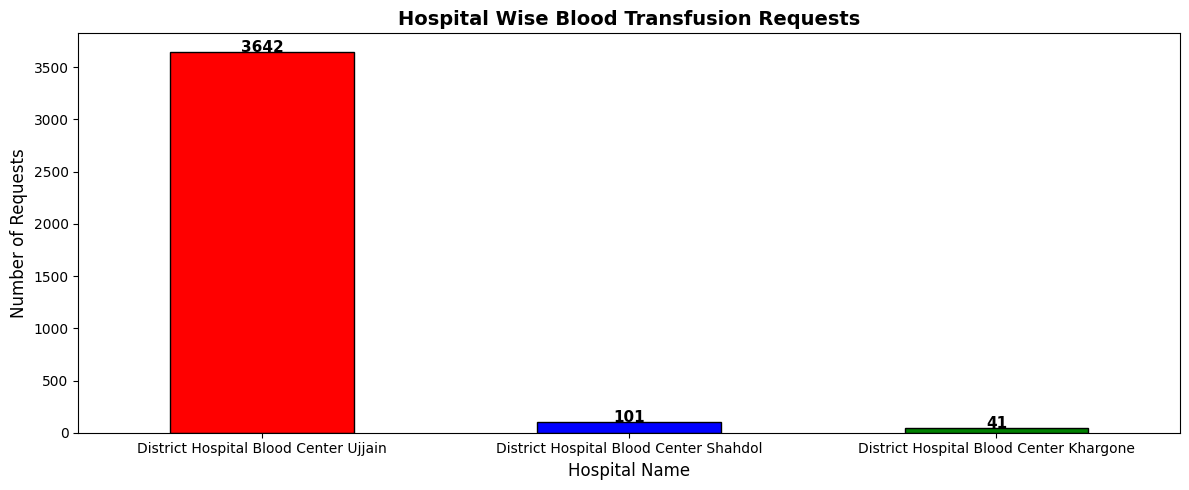

In [ ]:
# Graph 7 : Hospital Wise Requests

plt.figure(figsize=(12, 5))
hospital_counts = df_master_clean['Blood Bank Name'].value_counts()
colors = ['Red', 'Blue', 'Green']
hospital_counts.plot(kind='bar',
                     color=colors,
                     edgecolor='black')
plt.title('Hospital Wise Blood Transfusion Requests', fontsize=14, fontweight='bold')
plt.xlabel('Hospital Name', fontsize=12)
plt.ylabel('Number of Requests', fontsize=12)
plt.xticks(rotation=0)
for i, val in enumerate(hospital_counts):
    plt.text(i, val + 5, str(val), ha='center', fontsize=11, fontweight='bold')
plt.tight_layout()
plt.show()

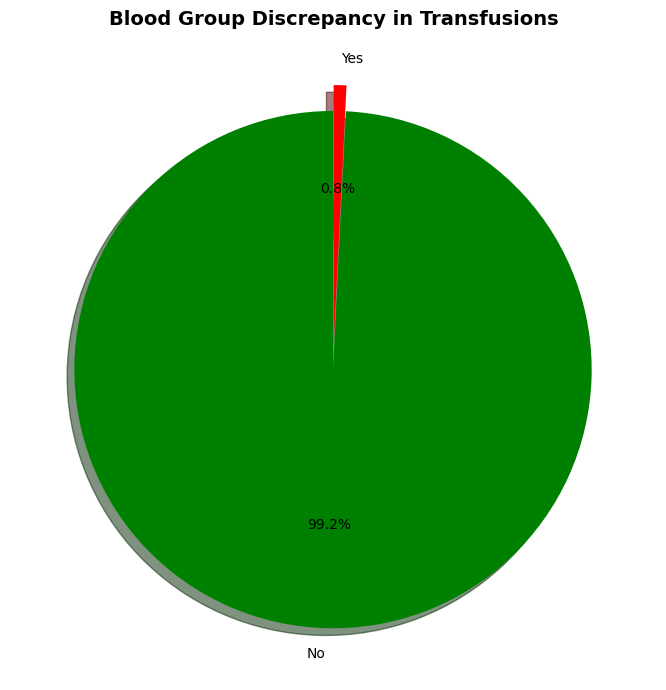

In [ ]:
# Graph 8 : Blood Group Discrepancy

plt.figure(figsize=(7, 7))
df_master_clean['Blood Group Discrepancy'] = df_master_clean['Blood Group Discrepancy'].fillna('No')
discrepancy_counts = df_master_clean['Blood Group Discrepancy'].value_counts()
colors = ['Green', 'Red']
plt.pie(discrepancy_counts,
        labels=discrepancy_counts.index,
        autopct='%1.1f%%',
        colors=colors,
        startangle=90,
        explode=(0.05, 0.05),
        shadow=True)
plt.title('Blood Group Discrepancy in Transfusions', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()